# Budget Optimisation

Owner: 

Input: 

Output: 

Budget Optimisation
Objective
The objective of this analysis is to determine the optimal allocation of advertising budgets across marketing channels in order to maximize expected marketing returns while operating under a fixed budget constraint.

In [1]:
import sys
sys.path.append('..')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.optimize import minimize

from src.predict import MMMPredictor

In [2]:
df = pd.read_csv(
    "../data/processed/feature_engineered_marketing_mix_data.csv"
)

df.head()

,month,country,brand_category,region_scope,tv_spend_lkr,facebook_instagram_spend_lkr,google_search_spend_lkr,youtube_spend_lkr,radio_spend_lkr,outdoor_spend_lkr,...,revenue_per_unit,revenue_per_conversion,roas,cost_per_conversion,lag_1_total_spend,lag_2_total_spend,rolling_3_month_spend,marketing_pressure,competitive_advantage,promotion_impact
0,2023-01-01,Sri Lanka,FMCG - Packaged Foods,National,4274762,3890003,2467793,1836858,1700676,1813444,...,558.637776,57.943069,4.386643,13.208977,0.0,0.0,0.000000e+00,12469416,50.4,7.8516
1,2023-02-01,Sri Lanka,FMCG - Packaged Foods,National,4023574,5062635,2962576,2254198,1922384,2941194,...,633.780115,110.710778,3.839737,28.832909,15983536.0,0.0,0.000000e+00,14302983,49.0,9.0912
2,2023-03-01,Sri Lanka,FMCG - Packaged Foods,National,5359091,3746337,4080535,2363737,1720670,2063917,...,562.908050,223.483184,4.399608,50.796156,19166561.0,15983536.0,1.816146e+07,15549700,54.1,6.8300
3,2023-04-01,Sri Lanka,FMCG - Packaged Foods,National,5102550,3690115,3390558,2595121,1217450,3091430,...,533.883913,81.452943,5.242138,15.538116,19334287.0,19166561.0,1.919602e+07,14778344,68.8,25.6088
4,2023-05-01,Sri Lanka,FMCG - Packaged Foods,National,4972723,5333813,3240078,2343364,1568285,3525300,...,461.062423,137.662905,3.693476,37.271909,19087224.0,19334287.0,1.980169e+07,15889978,47.0,2.1450


In [3]:
predictor = MMMPredictor(
    model_path="../outputs/models/ridge_mmm_baseline.joblib",
    config_path="../outputs/models/model_config.json",
    transform_params_path="../outputs/models/transformation_params.json"
)

print(type(predictor))

<class 'src.predict.MMMPredictor'>


Historical Budget Allocation

In [4]:
channels = [
    'tv_spend_lkr',
    'facebook_instagram_spend_lkr',
    'google_search_spend_lkr',
    'youtube_spend_lkr',
    'radio_spend_lkr',
    'outdoor_spend_lkr'
]

channels

['tv_spend_lkr',
 'facebook_instagram_spend_lkr',
 'google_search_spend_lkr',
 'youtube_spend_lkr',
 'radio_spend_lkr',
 'outdoor_spend_lkr']

In [5]:
from pathlib import Path

TABLES = Path("../outputs/tables"); TABLES.mkdir(parents=True, exist_ok=True)
FIGURES = Path("../outputs/figures"); FIGURES.mkdir(parents=True, exist_ok=True)

NICE = {"tv_spend_lkr": "TV", "facebook_instagram_spend_lkr": "Facebook/Instagram",
        "google_search_spend_lkr": "Google Search", "youtube_spend_lkr": "YouTube",
        "radio_spend_lkr": "Radio", "outdoor_spend_lkr": "Outdoor"}

df["month"] = pd.to_datetime(df["month"])
hist = df[df["month"] < "2025-01-01"]
plan = df[df["month"] >= "2025-01-01"].reset_index(drop=True)

# leftover ad effect at the end of 2024
_, carry_2024 = predictor.predict(hist, return_carryover=True)

current_spend = plan[channels].sum().values
BUDGET = current_spend.sum()
print(f"Planning period : {plan['month'].min():%b %Y} - {plan['month'].max():%b %Y} ({len(plan)} months)")
print(f"Fixed budget    : LKR {BUDGET:,.0f}")
pd.Series(current_spend / 1e6, index=[NICE[c] for c in channels]).round(2).to_frame("2025 spend (LKR M)")

Planning period : Jan 2025 - Dec 2025 (12 months)
Fixed budget    : LKR 240,285,900


,2025 spend (LKR M)
TV,56.54
Facebook/Instagram,54.49
Google Search,43.22
YouTube,30.64
Radio,22.01
Outdoor,33.39


## Objective Function
Given one multiplier per channel, return the model's total predicted sales for 2025.

In [6]:
def predicted_sales(mult):
    d = plan.copy()
    for ch, m in zip(channels, mult):
        d[ch] = plan[ch] * m
    return predictor.predict(d, initial_carryover=carry_2024).sum()

baseline_sales_2025 = predicted_sales(np.ones(len(channels)))
print(f"Predicted 2025 sales with the current split: LKR {baseline_sales_2025:,.0f}")

Predicted 2025 sales with the current split: LKR 1,041,497,107


## Rules (Constraints and Bounds)
- **Rule 1:** total spend = fixed budget.
- **Rule 2:** each channel stays between **70% and 130%** of its current spend.
- **Radio:** the model gives Radio a negative coefficient, which is not believable. Radio is kept at the budget level
  (not reallocated) until the Modelling team fixes the model.
- Numbers are scaled to **millions** so SLSQP can move properly.

In [7]:
LOWER, UPPER = 0.70, 1.30
coefs = pd.Series(predictor.model.named_steps["regression"].coef_, index=predictor.features)
NEGATIVE = [ch for ch in channels if coefs[f"{ch}_hill"] < 0]
print("Held at budget level (negative coefficient):", [NICE[c] for c in NEGATIVE])

def optimise(budget_scale=1.0, hold_negative=True, lower=LOWER, upper=UPPER):
    target = BUDGET * budget_scale
    bounds = [(lower, upper)] * len(channels)
    if hold_negative:
        for ch in NEGATIVE:
            bounds[channels.index(ch)] = (budget_scale, budget_scale)
    constraints = [{"type": "eq", "fun": lambda m: (m * current_spend).sum() / 1e6 - target / 1e6}]
    return minimize(lambda m: -predicted_sales(m) / 1e6,
                    x0=np.full(len(channels), budget_scale), method="SLSQP",
                    bounds=bounds, constraints=constraints,
                    options={"ftol": 1e-10, "maxiter": 1000})

Held at budget level (negative coefficient): []


## Run the Optimiser and Check the Result

In [8]:
result = optimise(1.0)
opt_mult = result.x
optimal_sales = predicted_sales(opt_mult)

print("Solver success :", result.success, "|", result.message)
print(f"Budget check   : LKR {(opt_mult * current_spend).sum():,.0f} (target {BUDGET:,.0f})")
print("Bounds check   :", bool(((opt_mult >= LOWER - 1e-6) & (opt_mult <= UPPER + 1e-6)).all()))
print("Not all zero   :", bool(np.abs(opt_mult - 1).max() > 1e-3))
print(f"Predicted sales: LKR {baseline_sales_2025/1e6:,.1f}M -> LKR {optimal_sales/1e6:,.1f}M")
print(f"Expected uplift: LKR {(optimal_sales - baseline_sales_2025)/1e6:+,.1f}M "
      f"({(optimal_sales/baseline_sales_2025 - 1)*100:+.2f}%) with the SAME budget")

Solver success : True | Optimization terminated successfully
Budget check   : LKR 240,285,900 (target 240,285,900)
Bounds check   : True
Not all zero   : True
Predicted sales: LKR 1,041.5M -> LKR 1,067.4M
Expected uplift: LKR +25.9M (+2.49%) with the SAME budget


### Sanity check
2,000 random plans that follow the same rules. None should beat the optimiser.

In [9]:
rng = np.random.default_rng(42)
free = [i for i, ch in enumerate(channels) if ch not in NEGATIVE]
fixed_spend = sum(current_spend[i] for i in range(len(channels)) if i not in free)
best_random, tries = -np.inf, 0
while tries < 2000:
    m = np.ones(len(channels)); m[free] = rng.uniform(LOWER, UPPER, len(free))
    m[free] *= (BUDGET - fixed_spend) / (m[free] * current_spend[free]).sum()
    if ((m[free] >= LOWER) & (m[free] <= UPPER)).all():
        best_random = max(best_random, predicted_sales(m)); tries += 1
print(f"Best random plan: LKR {best_random/1e6:,.2f}M | Optimiser: LKR {optimal_sales/1e6:,.2f}M "
      f"-> optimiser is better: {optimal_sales >= best_random}")

Best random plan: LKR 1,060.31M | Optimiser: LKR 1,067.42M -> optimiser is better: True


## Current vs Optimal Allocation

In [10]:
optimal_allocation = pd.DataFrame({
    "channel": [NICE[c] for c in channels], "channel_column": channels,
    "current_spend_lkr": current_spend, "optimal_spend_lkr": opt_mult * current_spend,
    "multiplier": opt_mult})
optimal_allocation["change_lkr"] = optimal_allocation["optimal_spend_lkr"] - optimal_allocation["current_spend_lkr"]
optimal_allocation["change_pct"] = (optimal_allocation["multiplier"] - 1) * 100
optimal_allocation["current_share_pct"] = optimal_allocation["current_spend_lkr"] / BUDGET * 100
optimal_allocation["optimal_share_pct"] = optimal_allocation["optimal_spend_lkr"] / BUDGET * 100
optimal_allocation["at_bound"] = np.select(
    [np.isclose(opt_mult, UPPER, atol=1e-3), np.isclose(opt_mult, LOWER, atol=1e-3)], ["max (+30%)", "min (-30%)"], "")
optimal_allocation["held_model_issue"] = optimal_allocation["channel_column"].isin(NEGATIVE)
optimal_allocation["predicted_sales_current_lkr"] = baseline_sales_2025
optimal_allocation["predicted_sales_optimal_lkr"] = optimal_sales

optimal_allocation.to_csv(TABLES / "optimal_allocation.csv", index=False)
print("Saved optimal_allocation.csv")

show = optimal_allocation[["channel", "current_spend_lkr", "optimal_spend_lkr", "change_pct", "at_bound"]].copy()
show[["current_spend_lkr", "optimal_spend_lkr"]] /= 1e6
show.rename(columns={"current_spend_lkr": "current (LKR M)", "optimal_spend_lkr": "optimal (LKR M)"}).round(2)

Saved optimal_allocation.csv


,channel,current (LKR M),optimal (LKR M),change_pct,at_bound
0,TV,56.54,60.20,6.49,
1,Facebook/Instagram,54.49,38.14,-30.00,min (-30%)
2,Google Search,43.22,56.18,30.00,max (+30%)
3,YouTube,30.64,39.83,30.00,max (+30%)
4,Radio,22.01,15.41,-30.00,min (-30%)
5,Outdoor,33.39,30.52,-8.60,


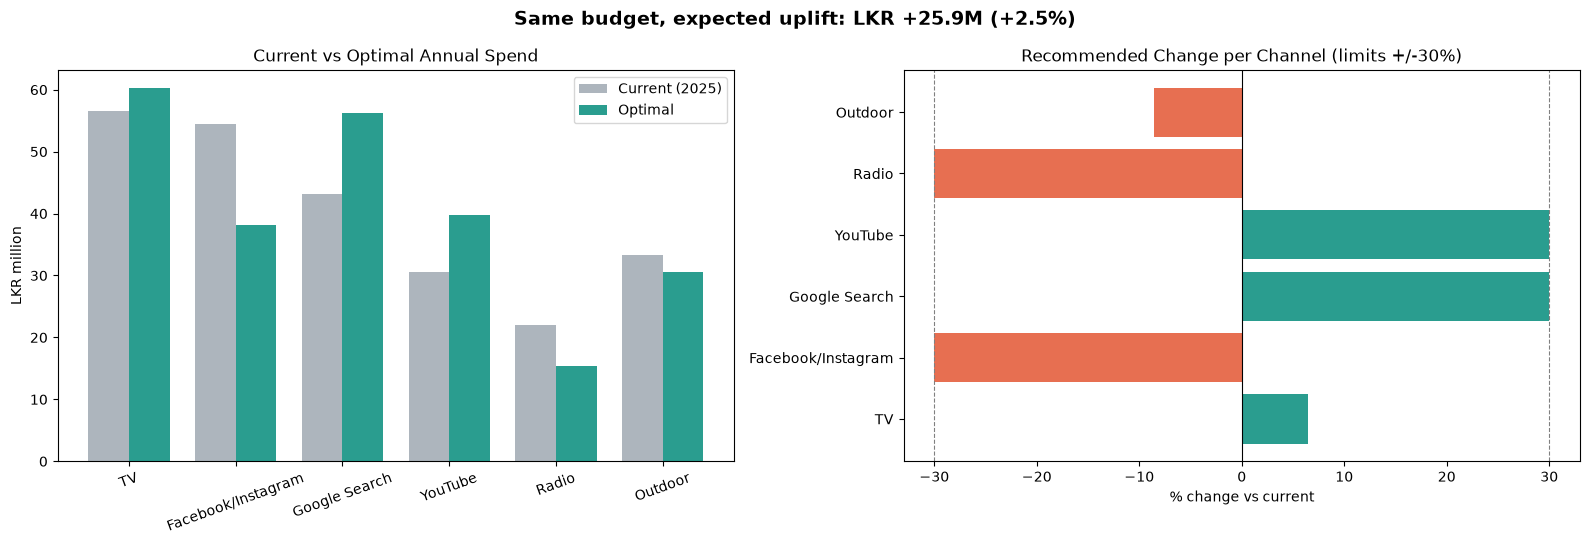

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))
x = np.arange(len(optimal_allocation)); w = 0.38
axes[0].bar(x - w/2, optimal_allocation["current_spend_lkr"] / 1e6, w, label="Current (2025)", color="#adb5bd")
axes[0].bar(x + w/2, optimal_allocation["optimal_spend_lkr"] / 1e6, w, label="Optimal", color="#2a9d8f")
axes[0].set_xticks(x, optimal_allocation["channel"], rotation=20)
axes[0].set(title="Current vs Optimal Annual Spend", ylabel="LKR million"); axes[0].legend()

pct = optimal_allocation["change_pct"]
axes[1].barh(optimal_allocation["channel"], pct,
             color=np.where(pct > 0, "#2a9d8f", np.where(pct < 0, "#e76f51", "#adb5bd")))
axes[1].axvline(0, color="black", lw=0.8)
for lim in (-30, 30):
    axes[1].axvline(lim, color="grey", ls="--", lw=0.8)
axes[1].set(title="Recommended Change per Channel (limits +/-30%)", xlabel="% change vs current")
fig.suptitle(f"Same budget, expected uplift: LKR {(optimal_sales - baseline_sales_2025)/1e6:+.1f}M "
             f"({(optimal_sales/baseline_sales_2025 - 1)*100:+.1f}%)", fontsize=14, fontweight="bold")
fig.tight_layout()
fig.savefig(FIGURES / "opt_01_current_vs_optimal.png", dpi=150, bbox_inches="tight")
plt.show()

## Budget Scenarios (-20% to +20%)
For each total budget, compare **today's split scaled up/down** with the **optimised split**.

In [12]:
rows = []
for s in [0.8, 0.9, 1.0, 1.1, 1.2]:
    r = optimise(s)
    cur_mix = predicted_sales(np.full(len(channels), s))
    opt = predicted_sales(r.x)
    row = {"scenario": f"{(s - 1) * 100:+.0f}%", "budget_multiplier": s, "total_budget_lkr": BUDGET * s,
           "sales_current_mix_lkr": cur_mix, "sales_optimal_mix_lkr": opt,
           "uplift_vs_current_mix_lkr": opt - cur_mix, "uplift_vs_current_mix_pct": (opt / cur_mix - 1) * 100,
           "solver_success": r.success}
    row.update({f"optimal_{c}": v for c, v in zip(channels, r.x * current_spend)})
    rows.append(row)
budget_scenarios = pd.DataFrame(rows)
budget_scenarios.to_csv(TABLES / "budget_scenarios.csv", index=False)
print("Saved budget_scenarios.csv")

show = budget_scenarios[["scenario", "total_budget_lkr", "sales_current_mix_lkr", "sales_optimal_mix_lkr",
                         "uplift_vs_current_mix_lkr", "solver_success"]].copy()
show[["total_budget_lkr", "sales_current_mix_lkr", "sales_optimal_mix_lkr", "uplift_vs_current_mix_lkr"]] /= 1e6
show.round(2)

Saved budget_scenarios.csv


,scenario,total_budget_lkr,sales_current_mix_lkr,sales_optimal_mix_lkr,uplift_vs_current_mix_lkr,solver_success
0,-20%,192.23,986.27,1003.68,17.41,True
1,-10%,216.26,1015.38,1039.79,24.40,True
2,+0%,240.29,1041.50,1067.42,25.92,True
3,+10%,264.31,1065.06,1088.39,23.33,True
4,+20%,288.34,1086.43,1101.62,15.19,False


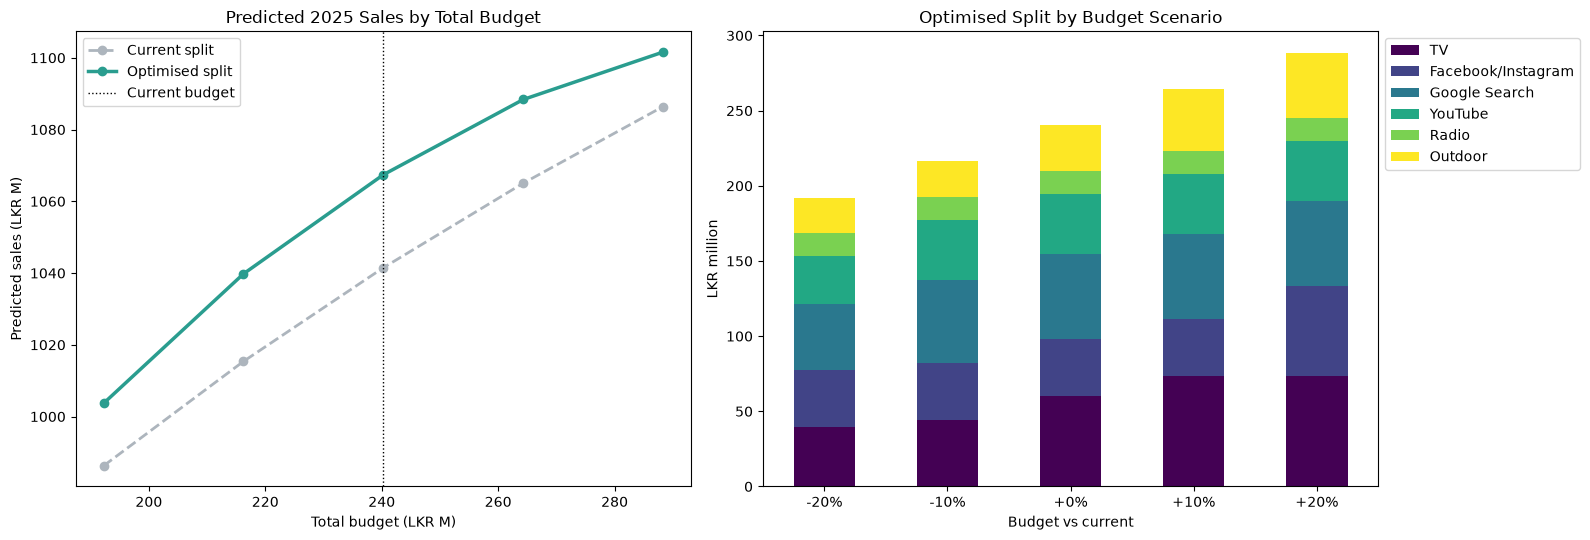

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))
axes[0].plot(budget_scenarios["total_budget_lkr"] / 1e6, budget_scenarios["sales_current_mix_lkr"] / 1e6,
             "o--", lw=2, color="#adb5bd", label="Current split")
axes[0].plot(budget_scenarios["total_budget_lkr"] / 1e6, budget_scenarios["sales_optimal_mix_lkr"] / 1e6,
             "o-", lw=2.5, color="#2a9d8f", label="Optimised split")
axes[0].axvline(BUDGET / 1e6, color="black", ls=":", lw=1, label="Current budget")
axes[0].set(title="Predicted 2025 Sales by Total Budget", xlabel="Total budget (LKR M)", ylabel="Predicted sales (LKR M)")
axes[0].legend()

stack = budget_scenarios.set_index("scenario")[[f"optimal_{c}" for c in channels]] / 1e6
stack.columns = [NICE[c] for c in channels]
stack.plot(kind="bar", stacked=True, ax=axes[1], colormap="viridis", rot=0)
axes[1].set(title="Optimised Split by Budget Scenario", xlabel="Budget vs current", ylabel="LKR million")
axes[1].legend(bbox_to_anchor=(1, 1))
fig.tight_layout()
fig.savefig(FIGURES / "opt_02_budget_scenarios.png", dpi=150, bbox_inches="tight")
plt.show()

In [14]:
base_row = df.iloc[-1:].copy()

base_row

,month,country,brand_category,region_scope,tv_spend_lkr,facebook_instagram_spend_lkr,google_search_spend_lkr,youtube_spend_lkr,radio_spend_lkr,outdoor_spend_lkr,...,revenue_per_unit,revenue_per_conversion,roas,cost_per_conversion,lag_1_total_spend,lag_2_total_spend,rolling_3_month_spend,marketing_pressure,competitive_advantage,promotion_impact
35,2025-12-01,Sri Lanka,FMCG - Packaged Foods,National,4014648,5343070,4370892,3178264,2169012,3251553,...,528.184996,47.02418,4.394043,10.701803,19369179.0,22733821.0,21476813.0,16906874,65.6,15.353687


In [15]:
current_budget = sum(
    base_row[c].iloc[0]
    for c in channels
)

print(
    f"Current Budget: "
    f"LKR {current_budget:,.2f}"
)

Current Budget: LKR 22,327,439.00


Optimization Objective
The objective is to maximize sales predicted by the Marketing Mix Model while maintaining the same total advertising budget.

In [16]:
def objective(x):

    row = base_row.copy()

    for i, channel in enumerate(channels):
        row[channel] = x[i]

    predicted_sales = predictor.predict(row)[0]

    return -predicted_sales

Budget Constraints

In [17]:
constraints = [
    {
        "type": "eq",
        "fun": lambda x:
        np.sum(x) - current_budget
    }
]

constraints

[{'type': 'eq', 'fun': <function __main__.<lambda>(x)>}]

Budget Bounds
Each channel budget is restricted to 70%–130% of its current spending level.

In [18]:
bounds = []

for channel in channels:

    spend = base_row[channel].iloc[0]

    bounds.append(
        (
            spend * 0.7,
            spend * 1.3
        )
    )

bounds

[(np.float64(2810253.5999999996), np.float64(5219042.4)),
 (np.float64(3740148.9999999995), np.float64(6945991.0)),
 (np.float64(3059624.4), np.float64(5682159.600000001)),
 (np.float64(2224784.8), np.float64(4131743.2)),
 (np.float64(1518308.4), np.float64(2819715.6)),
 (np.float64(2276087.0999999996), np.float64(4227018.9))]

In [19]:
initial_guess = [
    base_row[c].iloc[0]
    for c in channels
]

initial_guess

[np.int64(4014648),
 np.int64(5343070),
 np.int64(4370892),
 np.int64(3178264),
 np.int64(2169012),
 np.int64(3251553)]

Run Optimization

In [20]:
result = minimize(
    objective,
    initial_guess,
    method="SLSQP",
    bounds=bounds,
    constraints=constraints
)

print(result.success)
print(result.message)

True
Optimization terminated successfully


Optimized Budget Allocation

In [21]:
optimized_df = pd.DataFrame({
    "Channel": channels,
    "Current Budget": initial_guess,
    "Optimized Budget": result.x
})

optimized_df["Change"] = (
    optimized_df["Optimized Budget"]
    - optimized_df["Current Budget"]
)

optimized_df["Allocation %"] = (
    optimized_df["Optimized Budget"]
    / current_budget
) * 100

optimized_df

,Channel,Current Budget,Optimized Budget,Change,Allocation %
0,tv_spend_lkr,4014648,4.203181e+06,1.885327e+05,18.825181
1,facebook_instagram_spend_lkr,5343070,3.909522e+06,-1.433548e+06,17.509942
2,google_search_spend_lkr,4370892,5.682160e+06,1.311268e+06,25.449222
3,youtube_spend_lkr,3178264,3.679130e+06,5.008659e+05,16.478065
4,radio_spend_lkr,2169012,1.518308e+06,-6.507036e+05,6.800191
5,outdoor_spend_lkr,3251553,3.335139e+06,8.358587e+04,14.937400


In [22]:
optimized_df.to_csv(
    "../outputs/tables/optimized_budget_allocation.csv",
    index=False
)

Current vs Optimized Budget Comparison

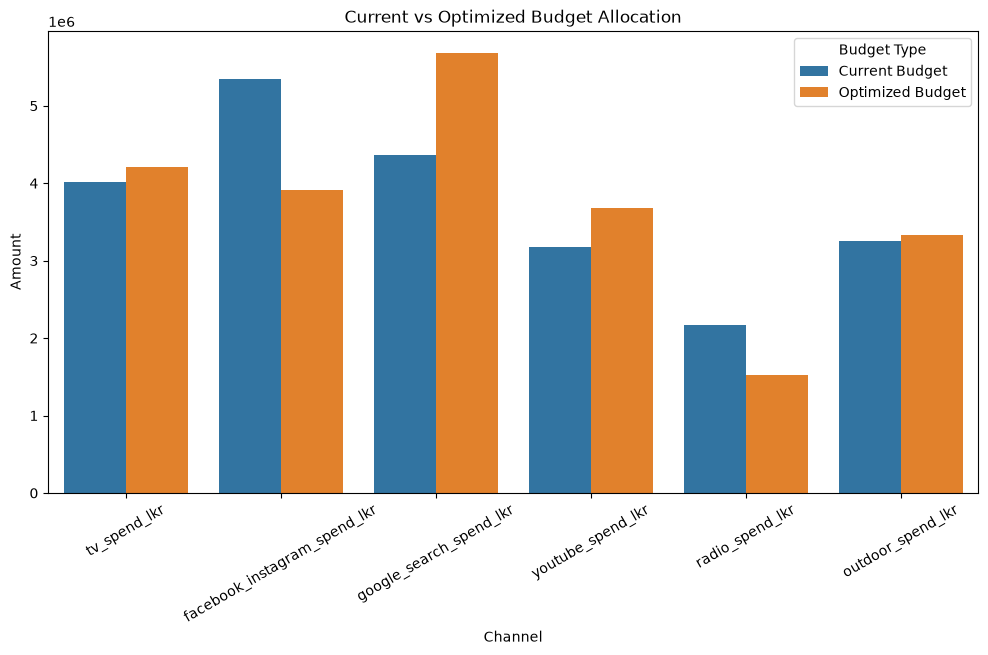

In [23]:
comparison_df = optimized_df.melt(
    id_vars="Channel",
    value_vars=[
        "Current Budget",
        "Optimized Budget"
    ],
    var_name="Budget Type",
    value_name="Amount"
)

plt.figure(figsize=(12,6))

sns.barplot(
    data=comparison_df,
    x="Channel",
    y="Amount",
    hue="Budget Type"
)

plt.title(
    "Current vs Optimized Budget Allocation"
)

plt.xticks(rotation=30)

plt.show()

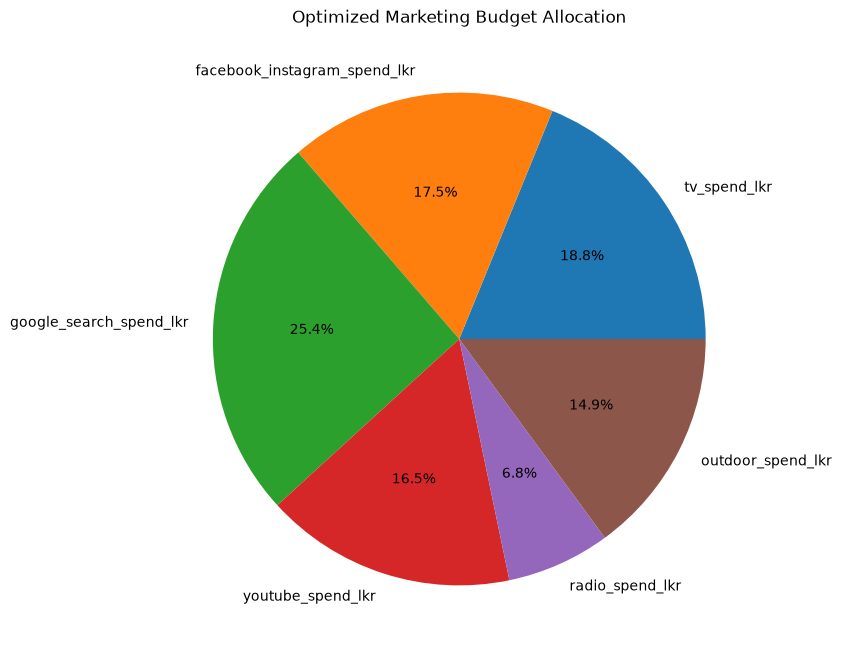

In [24]:
plt.figure(figsize=(8,8))

plt.pie(
    optimized_df["Optimized Budget"],
    labels=optimized_df["Channel"],
    autopct="%1.1f%%"
)

plt.title(
    "Optimized Marketing Budget Allocation"
)

plt.show()

## Key Findings

- **Budget:** The 2025 advertising budget of **LKR 240.3M** was kept fixed and re-split across the channels.
- **Expected uplift:** With the same budget, the optimised split raises predicted 2025 sales from **LKR 1,041.5M to LKR 1,067.4M**, an increase of about **LKR 25.9M (+2.5%)**.
- **Recommended changes:**

| Channel | Change | Amount (LKR M) |
|---|---|---|
| Google Search | **+30%** (at the upper limit) | +13.0 |
| YouTube | **+30%** (at the upper limit) | +9.2 |
| TV | +6% | +3.7 |
| Outdoor | -9% | -2.9 |
| Radio | **-30%** (at the lower limit) | -6.6 |
| Facebook/Instagram | **-30%** (at the lower limit) | -16.3 |

- Google Search, YouTube, Facebook/Instagram and Radio reached the ±30% limits, which means the optimiser would move even further if allowed.
- **Checks:** The optimiser finished successfully, the total equals the budget, every channel stays within 70%–130%, and no random plan out of 2,000 gave higher sales.
- **Budget scenarios:** At every budget level, the optimised split gives more sales than today's split. With a **10% smaller budget**, the optimised split gives about the same sales as today's full budget (LKR 1,039.8M vs 1,041.5M), saving about LKR 24M. A **10% larger budget** with the optimised split adds about **LKR 46.9M** compared with today.

## Recommendations

- **Move budget from Facebook/Instagram and Radio to Google Search and YouTube,** following the optimised split. This is expected to add about LKR 26M in sales with no extra spending.
- **Increase TV slightly (+6%) and reduce Outdoor slightly (-9%).**
- **Make the changes gradually** (within ±30% per channel per year), and track results each month.
- **Improve the split before increasing the budget.** A better split alone gives about the same sales as a 10% bigger budget with today's split.
- **If the budget is increased,** put the extra money mainly into Google Search and YouTube first.
- **Radio:** the model finds no measurable effect, so the optimiser reduces it. Confirm this with a real-world test before cutting Radio further.
- **Re-run the optimisation every year** with new data, as channel performance and saturation levels will change.

## Conclusion

The budget optimisation used the Marketing Mix Model (with non-negative media effects) to predict sales for the whole of 2025, including the carry-over effect of advertising from 2024, and SciPy's SLSQP optimiser to find the best split under a fixed budget and ±30% limits per channel. Shifting budget towards Google Search and YouTube and away from Facebook/Instagram and Radio raises predicted sales by about LKR 25.9M (+2.5%) with the same budget. The scenario analysis shows that splitting the budget better is as valuable as increasing it by about 10%.